# 03 · Efeitos fixos de preço e promoção

No segundo passo da seleção por etapas (*step-up*), os preditores da observação semanal entram na parte fixa (Raudenbush & Bryk, 2002). São mantidos os interceptos aleatórios de loja, produto e par loja × produto do modelo nulo M4. Os modelos foram ajustados nas 104 semanas iniciais de treino (D11 revisada). As 52 semanas finais formam a janela de avaliação temporal retrospectiva com exposição exploratória prévia.

As duas versões do notebook leem as execuções gravadas em `outputs/runs` por `scripts/fit_fixed_effects.py` e pelos scripts de sensibilidade. Os coeficientes representam associações condicionais em semanas com transações registradas.

*Dados: dunnhumby Source Files – Breakfast at the Frat.*

In [1]:
LANG = "pt"

In [2]:
import warnings

import pandas as pd
from IPython.display import display

from retail_multilevel import interpret, viz
from retail_multilevel.i18n import t
from retail_multilevel.paths import PROCESSED_DIR
from retail_multilevel.runs import load_run
from retail_multilevel.split import model_sample

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.4f}".format)
run = load_run("fixed_effects", "20261124-114202-1fda5a5d")
print(t("data_credit", LANG))
print("run:", run.run_id, "| finished_at:", run.metadata["finished_at"])
sample = run.load_json("sample")
display(pd.Series(sample).to_frame("training sample"))

Dados: dunnhumby Source Files – Breakfast at the Frat
run: 20261124-114202-1fda5a5d | finished_at: 2026-11-24T11:45:14.599134


,training sample
nobs,347092
n_fallback_rows_in_train,111
excluded_fallback,False
n_pairs,3859
log_disc_mean,-0.0688
log_disc_sd,0.1468
share_disc_below_5pct,0.2501


O identificador e o horário de término da execução são mostrados acima. O treino reúne 347.092 linhas em 3.859 pares loja × produto. `LOG_DISC`, o logaritmo da razão entre preço e preço base, tem média de −0,069 e desvio-padrão de 0,147. Em 25,0% das linhas de treino, `LOG_DISC` fica abaixo de −0,05, o equivalente a um desconto de cerca de 5% ou mais. Em 111 linhas, o preço base foi preenchido com o preço observado (`BASE_PRICE = PRICE`). A seção 8 avalia a sensibilidade a essa regra.

## 1. A especificação

A variável-resposta é log(unidades). As decisões D12 a D14 definem a parte fixa com base na exploração inicial do painel (D11 revisada). Como o log do preço varia sobretudo entre produtos, uma diferença de preço também pode refletir características dos produtos. Por isso o preço foi decomposto em três termos. `LOG_DISC = log(preço / preço base)` mede o desconto temporário e seu coeficiente estima a elasticidade ao desconto (Tellis, 1988; Bijmolt et al., 2005). `LOG_BASE_DEV` mede o desvio do log do preço regular em relação à média do próprio par e seu coeficiente estima a associação com mudanças do preço regular dentro do par ao longo do tempo. `LOG_BASE_MEAN` é a média do log do preço regular do par. Esse termo de Mundlak separa a associação com o nível médio de preço das mudanças dentro do par (Mundlak, 1978). As médias foram calculadas com as linhas de treino. Os valores ausentes de preço base foram preenchidos pela regra D8 revisada, que usa o histórico anterior do par quando disponível.

O desconto e os indicadores de promoção (`FEATURE`, `DISPLAY` e `TPR_ONLY`, todos 0 ou 1) entram sem decomposição entre e dentro de pares. A seção 9 reestima essas associações com efeitos fixos de par e de semana. Cada indicador de promoção é interpretado com o desconto mantido constante. Como o preço fica abaixo do base só em semanas com promoção, são poucas as faixas de desconto em que certas promoções podem ser comparadas (seção 4). Três pares de termos de Fourier (`SIN_k` e `COS_k`, com k de 1 a 3) representam a sazonalidade da semana do ano, e `TREND` representa a tendência linear em anos. O perfil de Fourier é comum a todo o painel e usa seis coeficientes para os dois anos de treino (Hyndman & Athanasopoulos, 2021).

Os testes de razão de verossimilhanças (LR) que comparam parte fixa diferente usam ajustes por **máxima verossimilhança (ML)**, porque a verossimilhança restrita (REML) depende da parte fixa e, por isso, não é comparável entre esses modelos (Pinheiro & Bates, 2000). Os coeficientes e as variâncias do modelo final, por sua vez, vêm de um novo ajuste por REML (Bates et al., 2015), que estima as variâncias com menos viés. Os quatro modelos, de F0 a F3, são mostrados a seguir.

In [3]:
fits = run.load_table("fits")
display(fits[["name", "formula"]])

,name,formula
0,F0_null,LOG_UNITS ~ 1 + (1 | STORE_NUM) + (1 | UPC) + (1 | STORE_NUM:UPC)
1,F1_price,LOG_UNITS ~ 1 + LOG_DISC + LOG_BASE_DEV + LOG_BASE_MEAN + (1 | STORE_NUM) + (1 | UPC) + (1 | STORE_NUM:UPC)
2,F2_promo,LOG_UNITS ~ 1 + LOG_DISC + LOG_BASE_DEV + LOG_BASE_MEAN + FEATURE + DISPLAY + TPR_ONLY + (1 | STORE_NUM) + (1 | UPC) + (1 | STORE_NUM:UPC)
3,F3_season,LOG_UNITS ~ 1 + LOG_DISC + LOG_BASE_DEV + LOG_BASE_MEAN + FEATURE + DISPLAY + TPR_ONLY + TREND + SIN_1 + COS_1 + SIN_2 + COS_2 + SIN_3 + COS_3 + (1 | STORE_NUM) + (1 | UPC) + (1 | STORE_NUM:UPC)


## 2. O step-up dos efeitos fixos

Cada passo acrescenta um bloco de termos à parte fixa: o preço (F1), as promoções (F2) e a sazonalidade com tendência (F3). A tabela traz o número de parâmetros, a log-verossimilhança ML, o AIC, o BIC e o número de mensagens de convergência.

In [4]:
display(fits[["name", "nobs", "npar", "loglik", "aic", "bic", "n_messages"]])

,name,nobs,npar,loglik,aic,bic,n_messages
0,F0_null,347092,5,"-346,785.4346","693,580.8691","693,634.6559",0
1,F1_price,347092,8,"-295,885.3621","591,786.7242","591,872.7830",0
2,F2_promo,347092,11,"-275,144.9318","550,311.8637","550,430.1945",0
3,F3_season,347092,18,"-274,532.4014","549,100.8028","549,294.4350",0


A log-verossimilhança ML sobe de −346.785 (F0) para −295.885 (F1), −275.145 (F2) e −274.532 (F3), e o AIC cai de 693.581 para 591.787, 550.312 e 549.101, com 5, 8, 11 e 18 parâmetros. O BIC também diminui a cada passo (de 693.635 para 549.294), de modo que a penalização por parâmetros adicionais não reverte nenhum dos ganhos. Nenhum ajuste gerou mensagens de convergência.

In [5]:
lr = run.load_table("lr")


def format_p(p):
    return "< 1e-300" if p < 1e-300 else f"{p:.2e}"


display(lr.assign(p_value=lr["p_value"].map(format_p), p_naive=lr["p_naive"].map(format_p)))

,restricted,full,stat,df,p_value,p_naive
0,F0_null,F1_price,"101,800.1449",3,< 1e-300,< 1e-300
1,F1_price,F2_promo,"41,480.8605",3,< 1e-300,< 1e-300
2,F2_promo,F3_season,"1,225.0609",7,2.69e-260,2.69e-260


Aqui, ao contrário do notebook 02, os testes não envolvem variâncias na fronteira do espaço de parâmetros: são efeitos fixos, e a referência é um χ² comum, razão pela qual `p_value` e `p_naive` coincidem. As estatísticas são de 101.800 (F0 contra F1, 3 graus de liberdade), 41.481 (F1 contra F2, 3 graus) e 1.225 (F2 contra F3, 7 graus). Os dois primeiros valores p são menores que 1e-300 e o terceiro é de 2,69e-260.

Os 347.092 registros de treino dão aos testes sensibilidade para detectar contribuições pequenas. Pela estatística de razão de verossimilhanças, o bloco de preço acrescenta mais ao ajuste (101.800), seguido pelo de promoções (41.481). A estatística do bloco de sazonalidade e tendência (1.225) é cerca de 1/83 da do preço.

## 3. Os coeficientes e o que significam

O gráfico mostra os coeficientes do modelo final (F3, por REML) com intervalos de 95% de Wald, na escala logarítmica, sem o intercepto e sem os termos de Fourier. Os intervalos são tão estreitos que mal se distinguem do ponto, mas são condicionais à especificação do F3 e subestimam a incerteza, como mostram as seções 9 e 10.

,term,estimate,std_error,z,ci_low,ci_high
0,(Intercept),2.9610,0.1749,16.9260,2.6181,3.3039
1,LOG_DISC,-1.6852,0.0107,-157.4917,-1.7062,-1.6642
2,LOG_BASE_DEV,-1.5921,0.0119,-133.9563,-1.6154,-1.5688
3,LOG_BASE_MEAN,-0.8797,0.1054,-8.3477,-1.0862,-0.6731
4,FEATURE,0.4972,0.0043,116.2815,0.4889,0.5056
5,DISPLAY,0.4087,0.0036,113.3137,0.4016,0.4157
6,TPR_ONLY,-0.0412,0.0037,-11.0859,-0.0485,-0.0339
7,TREND,-0.0214,0.0018,-12.2339,-0.0249,-0.0180


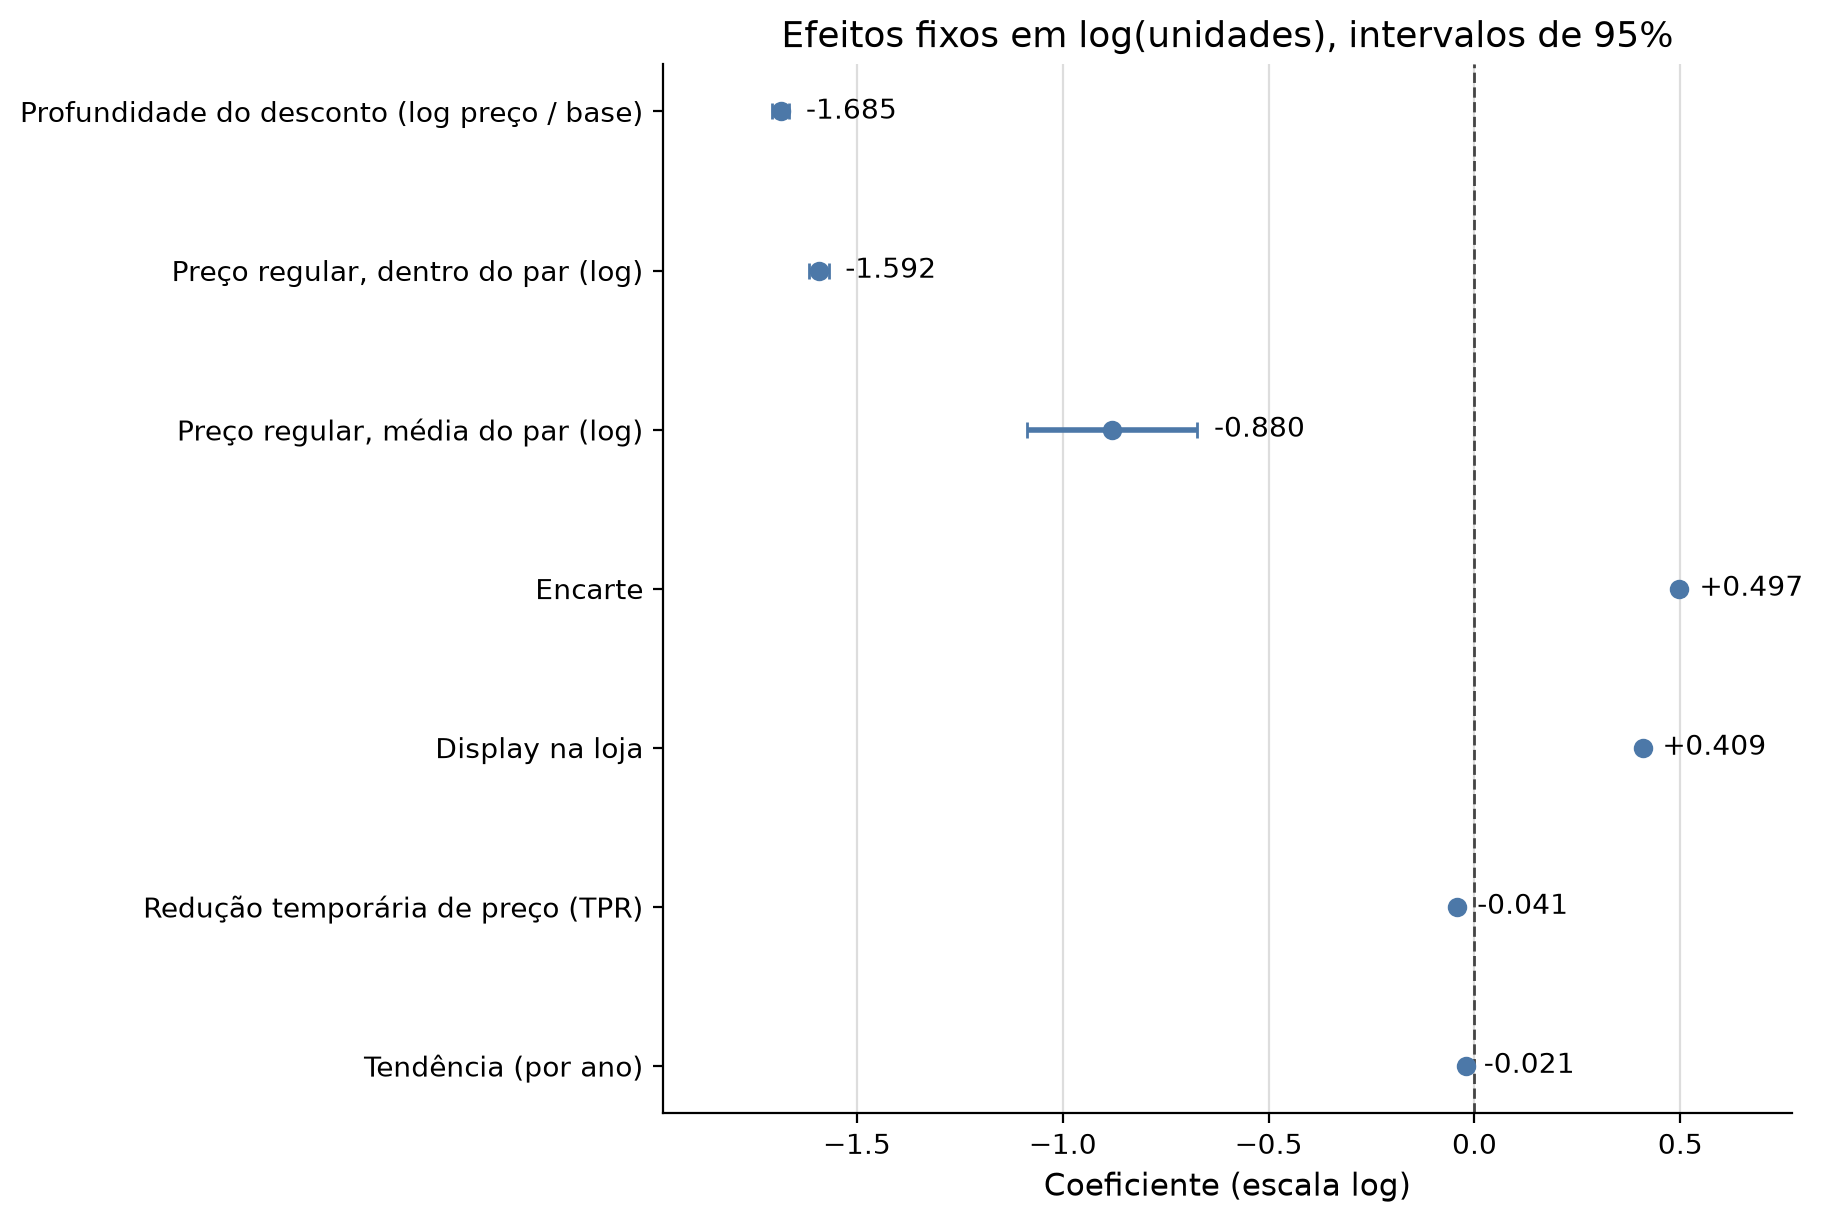

In [6]:
fixef = run.load_table("fixef")
fig = viz.plot_coefficients(fixef, LANG)
display(fixef[~fixef["term"].str.startswith(("SIN_", "COS_"))])

A tabela converte coeficientes e limites de confiança para variações percentuais nas unidades. A comparação usa uma redução de 10% na razão entre preço e preço base, um aumento de 10% no preço regular, a presença de cada promoção ou a passagem de um ano. Em cada linha, as demais covariáveis ficam constantes.

In [7]:
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(interpret.effects_table(fixef, LANG))

,Efeito,Variação nas unidades (%),"IC de 95%, inferior (%)","IC de 95%, superior (%)"
0,Desconto 10% mais profundo,19.4,19.2,19.7
1,Preço regular 10% maior,-14.1,-14.3,-13.9
2,"Encarte, além da redução de preço",64.4,63.0,65.8
3,"Display na loja, além da redução de preço",50.5,49.4,51.5
4,"Apenas TPR, além da redução de preço",-4.0,-4.7,-3.3
5,Um ano a mais (tendência),-2.1,-2.5,-1.8


O coeficiente do desconto é −1,685 (IC 95% de Wald: −1,706 a −1,664), de modo que uma redução de 10% na razão entre preço e preço base está associado a cerca de 19,4% mais unidades (IC 95%: 19,2% a 19,7%). O preço regular, medido dentro do par, tem coeficiente −1,592, e um preço regular 10% maior está associado a cerca de 14,1% menos unidades. O encarte tem coeficiente 0,497, ou seja, cerca de 64,4% mais unidades, e o display, 0,409, ou cerca de 50,5% mais, ambos com o desconto e as demais covariáveis mantidos constantes. A tendência é de −0,021 por ano, cerca de 2,1% menos unidades a cada ano.

O coeficiente de `TPR_ONLY` é −0,041, ou seja, −4,0% nas unidades (IC 95%: −4,7% a −3,3%). Esse valor é a transformação do coeficiente da flag com a profundidade do desconto e as demais covariáveis mantidas constantes, isto é, a comparação entre duas semanas com o mesmo desconto, uma marcada como TPR e outra sem promoção. Essa comparação praticamente não existe nos dados de treino: as 47.610 linhas `TPR_ONLY` têm todas desconto (nenhuma abaixo de 5%, como mostra a tabela cruzada da seção 4), e nenhuma das 247.331 linhas sem promoção tem preço abaixo do base. Comparar TPR com uma semana sem promoção na mesma faixa de desconto é, portanto, uma extrapolação, que depende da forma funcional aditiva do modelo. O coeficiente, por si só, não permite afirmar que a TPR reduz as vendas nem que o seu valor vem apenas do desconto. A leitura de negócio exige cenários que combinem a profundidade do desconto e o tipo de promoção, apresentados na seção 4.

Os coeficientes de encarte e de display contrastam com os lifts brutos (Blattberg & Neslin, 1989) do notebook 01 (encarte +195%, display +129% e TPR +33%). Naquele notebook, as comparações eram descritivas e misturavam a promoção com o corte de preço que a acompanha. Aqui, a profundidade do desconto, o nível de preço regular, a tendência e a sazonalidade são controlados, e o que resta para o encarte (+64%) e o display (+50%) é uma fração do lift bruto: uma parte do que parecia efeito da promoção acompanha o corte de preço.

O coeficiente de `LOG_BASE_MEAN` (−0,880, IC 95%: −1,086 a −0,673) merece uma leitura distinta. Ele compara pares com preços regulares médios diferentes e, por isso, é uma associação **entre pares**, de natureza composicional (pares com preço regular médio mais alto tendem a vender menos unidades por semana), e não o efeito de alterar o preço de um item.

## 4. Cenários conjuntos de desconto e promoção

As combinações de desconto e promoção são usadas para comparar cenários de negócio. A tabela cruzada conta as linhas de treino por tipo de promoção e faixa de desconto (`1 − PRICE / BASE_PRICE`).

In [8]:
panel = pd.read_parquet(PROCESSED_DIR / "panel.parquet")
train = model_sample(panel, "train")
display(interpret.promo_by_discount_band(train, LANG))

,Sem redução de preço,0-5%,5-10%,10-20%,20-30%,Acima de 30%
Sem promoção,247331,0,0,0,0,0
Apenas TPR,0,0,155,26592,11992,8871
Apenas encarte,793,846,835,3871,4128,3922
Apenas display,8489,2148,1198,5085,3138,3129
Encarte e display,265,454,728,3025,4431,5666


Nenhuma das 247.331 linhas sem promoção tem desconto, e nenhuma das 47.610 linhas de TPR tem desconto de até 5%: 155 ficam entre 5% e 10%, e a maior parte, 26.592, entre 10% e 20%. Encarte e display ocorrem, ao contrário, em todas as faixas, inclusive sem redução de preço (793 linhas só de encarte e 8.489 só de display).

Cada cenário abaixo é medido em relação a uma semana regular, sem desconto e sem promoção, por `exp(β_desconto · log(1 − d) + β_promoção) − 1`, com as demais covariáveis mantidas constantes. As duas últimas colunas contam as linhas de treino que realizam exatamente a combinação de promoção do cenário com desconto a até 3 pontos percentuais do valor do cenário, o que indica se o cenário está dentro das faixas observadas. Os valores são estimativas pontuais: a tabela de coeficientes não guarda as covariâncias, e os intervalos individuais não podem ser combinados.

In [9]:
scenarios = interpret.DEFAULT_SCENARIOS
scenario_tab = interpret.scenario_table(
    interpret.scenario_effects(fixef, scenarios), interpret.scenario_support(train, scenarios, tol=0.03), LANG
)
with pd.option_context("display.float_format", "{:,.1f}".format):
    display(scenario_tab)

,Cenário,Desconto (%),Variação nas unidades vs. semana regular (%),Linhas de treino que o realizam,Participação nas linhas de treino (%)
0,Semana regular (sem desconto nem promoção),0.0,0.0,247331,71.3
1,TPR com 10% de desconto,10.0,14.6,9393,2.7
2,TPR com 20% de desconto,20.0,39.8,10185,2.9
3,"Encarte, sem desconto",0.0,64.4,1055,0.3
4,Encarte com 20% de desconto,20.0,139.5,2574,0.7
5,"Display, sem desconto",0.0,50.5,8622,2.5
6,Display com 20% de desconto,20.0,119.2,2272,0.7
7,Encarte e display com 25% de desconto,25.0,301.8,2767,0.8


Em relação à semana regular, uma TPR com 10% de desconto está associada a 14,6% mais unidades (9.393 linhas de treino, 2,7%). Com 20%, a diferença estimada é de 39,8% (10.185 linhas, 2,9%). Encarte com 20% (+139,5%, 2.574 linhas), display com 20% (+119,2%, 2.272 linhas) e encarte com display e 25% (+301,8%, 2.767 linhas) têm entre 0,7% e 0,8% das linhas cada. Sem desconto, o display está associado a +50,5% (8.622 linhas, 2,5%) e o encarte a +64,4% (1.055 linhas, 0,3%). O encarte sem desconto tem o menor suporte observado.

Os valores dependem da forma funcional. A elasticidade é constante em log(1 − d), as flags e o desconto são aditivos na escala logarítmica, e encarte e display não têm interação estimada: o valor de 301,8% para encarte com display é o produto dos efeitos estimados em separado (e^0,497 × e^0,409 × 0,75^−1,685 − 1), embora haja linhas dessa combinação em todas as faixas de desconto. O contraste entre TPR e display com o mesmo desconto de 20% (+39,8% contra +119,2%) usa linhas observadas nos dois cenários, mas continua sendo uma associação condicional, sujeita à seleção de quando e onde cada promoção é aplicada. Nenhum ranking de rentabilidade decorre desses números: a margem e o custo das promoções não estão nos dados, e uma recomendação de preço ou um ROI incremental exigiria identificação causal e dados de margem. A camada de decisão do projeto é, por isso, uma análise de cenários.

## 5. Sazonalidade e tendência

Os seis termos de Fourier são combinados em um perfil sazonal, expresso como a diferença percentual nas unidades em relação à semana média do ano.

,week_of_year,effect_pct
28,29,-4.2231
1,2,6.6175


,term,estimate,std_error,z,ci_low,ci_high
8,SIN_1,-0.0017,0.0014,-1.2547,-0.0044,0.0010
9,COS_1,0.0337,0.0013,26.6984,0.0313,0.0362
10,SIN_2,-0.0037,0.0013,-2.9136,-0.0062,-0.0012
11,COS_2,0.0148,0.0013,11.7528,0.0123,0.0173
12,SIN_3,0.0183,0.0013,14.4553,0.0158,0.0208
13,COS_3,0.0107,0.0013,8.4942,0.0082,0.0132


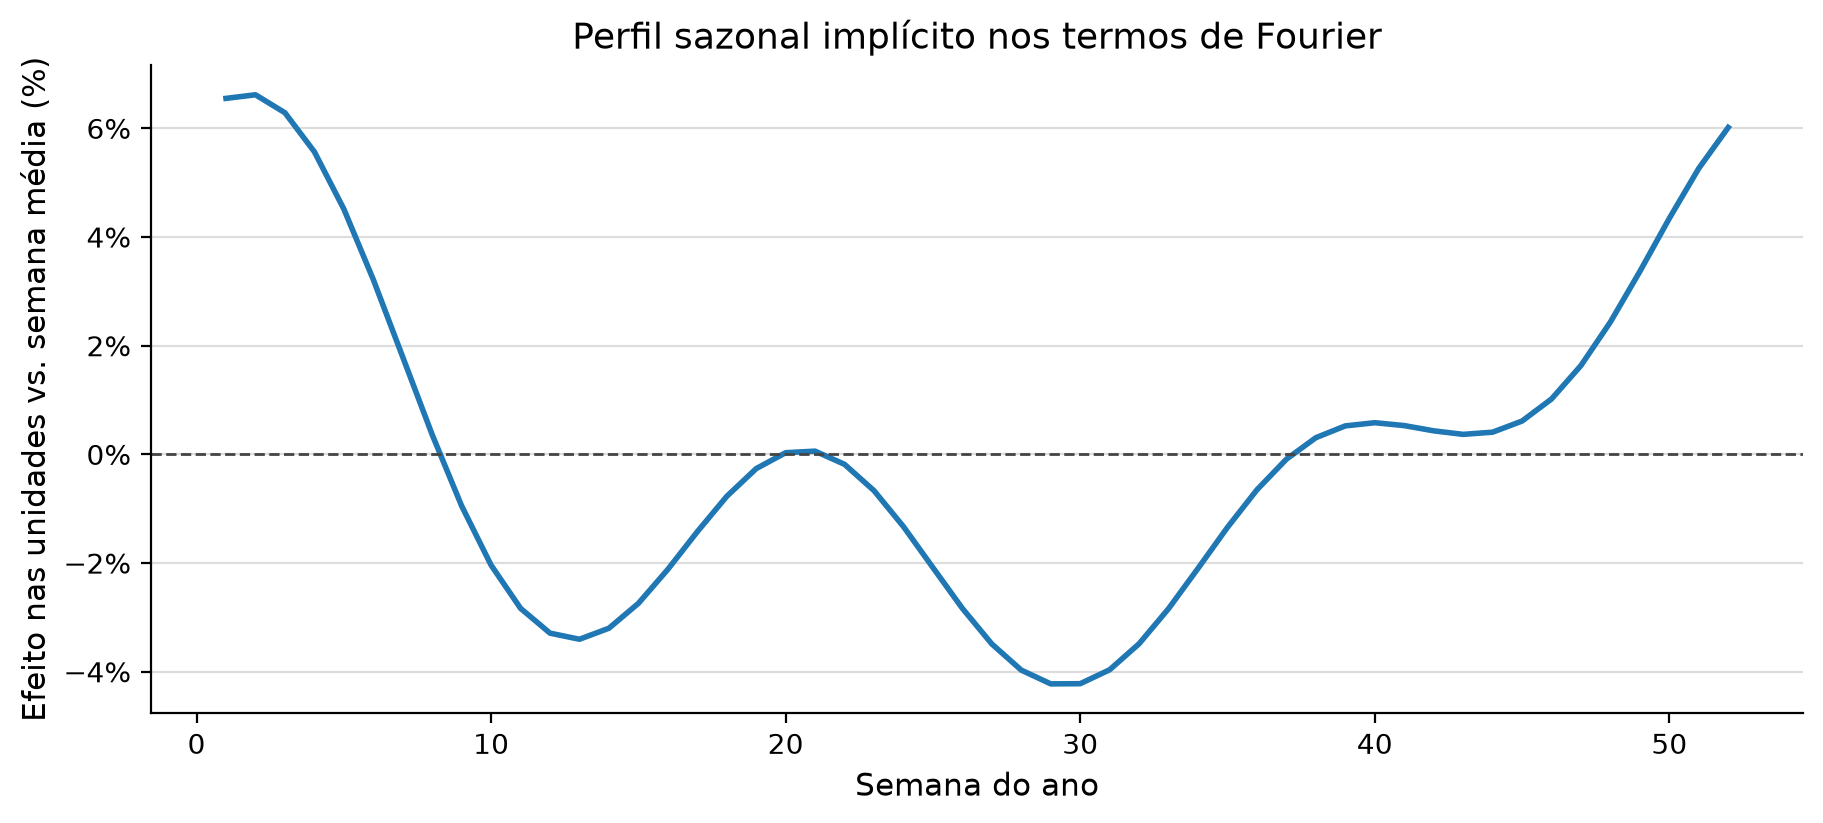

In [10]:
profile = interpret.seasonal_profile(fixef)
fig = viz.plot_seasonality(profile, LANG)
display(profile.loc[[profile["effect_pct"].idxmin(), profile["effect_pct"].idxmax()]])
display(fixef[fixef["term"].str.startswith(("SIN_", "COS_"))])

A amplitude da sazonalidade é pequena frente às associações de preço e de promoção: a semana mais fraca do ano (a semana 29) tem cerca de 4,2% menos unidades que a semana média, e a mais forte (a semana 2), cerca de 6,6% mais. A diferença entre os extremos é de cerca de 11 pontos percentuais, frente aos 19,4% associados a uma redução de 10% na razão entre preço e preço base. Alguns termos individuais têm coeficientes pequenos (por exemplo, `SIN_1`, −0,002, cujo intervalo inclui o zero), mas o bloco como um todo é claramente diferente de zero pelo teste de razão de verossimilhanças (1.225). A tendência, por fim, é de uma queda de cerca de 2,1% por ano (IC 95%: −2,5% a −1,8%) nas duas temporadas de treino, após o controle de preço, promoção e sazonalidade.

## 6. Quanto da variância preço e promoção explicam: pseudo-R² por nível

Em modelos multinível, a redução proporcional de cada componente de variância, do modelo nulo para o modelo final, informa em que nível os preditores atuam (Raudenbush & Bryk, 2002). O cálculo usa os ajustes por REML de F0 e F3, e a redução é 1 − variância final / variância do modelo nulo.

,group,var_null,var_final,reduction
0,Loja × produto,0.1431,0.1490,-0.0418
1,Loja,0.1623,0.1665,-0.0260
2,Produto,0.9646,0.6815,0.2934
3,Resíduo,0.4151,0.2724,0.3437


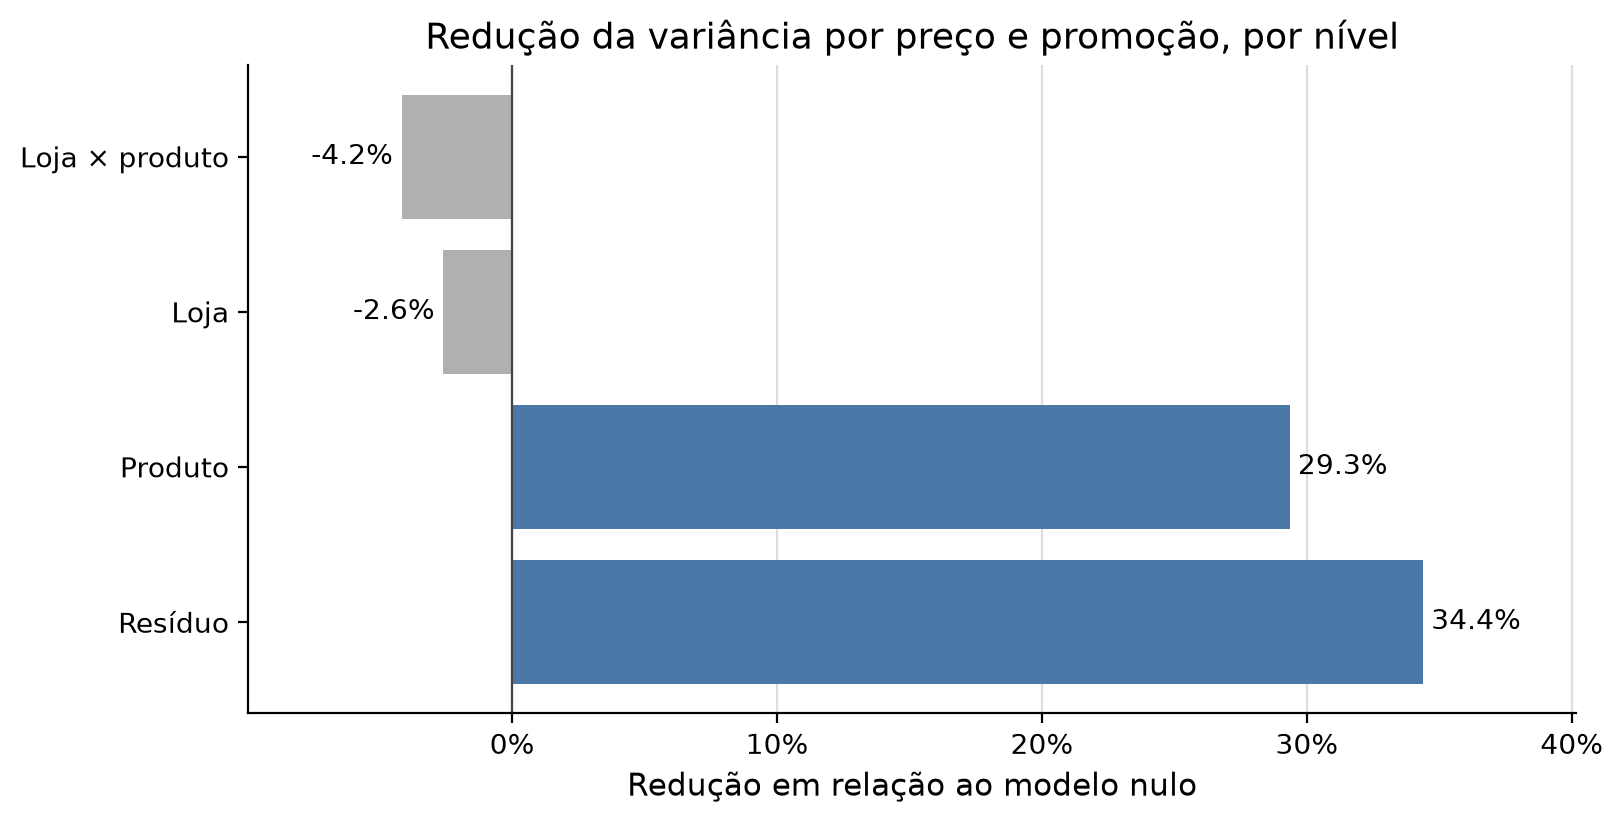

In [11]:
pseudo = run.load_table("pseudo_r2")
fig = viz.plot_pseudo_r2(pseudo, LANG)
display(pseudo.assign(group=pseudo["group"].map(lambda g: viz.group_label(g, LANG))))

O resíduo, que representa o movimento semana a semana dentro do par, cai 34,4% (de 0,415 para 0,272), de modo que preço e promoção explicam cerca de um terço da variância semanal dentro do par. A variância de produto cai 29,3% (de 0,965 para 0,682): como o nível de preço regular distingue os produtos, isso é consistente com o preço médio do par explicando parte da diferença entre produtos. Já as variâncias de loja (−2,6%) e de par (−4,2%) aumentam levemente.

Os pseudo-R² negativos correspondem a aumentos pequenos nos componentes estimados de loja e par. Ao acrescentar preditores, a variância pode se redistribuir entre os níveis. Neste ajuste, as maiores reduções ocorreram no resíduo e no componente de produto.

## 7. Nível único contra multinível

A mesma parte fixa do F3 foi ajustada de duas formas de nível único (Gelman & Hill, 2007): um OLS agrupado, que ignora a hierarquia, e um OLS com efeitos fixos de produto (variáveis binárias de UPC). O gráfico compara as estimativas dos quatro coeficientes mais relevantes (ponto ± 1,96 erro-padrão) nos três métodos, e a tabela traz os valores.

method,ols_pooled,ols_upc_fe,multilevel
term,,,
LOG_DISC,-0.3588,-1.4052,-1.6852
LOG_BASE_DEV,-0.9921,-1.4592,-1.5921
FEATURE,0.9080,0.4541,0.4972
DISPLAY,0.6507,0.5511,0.4087


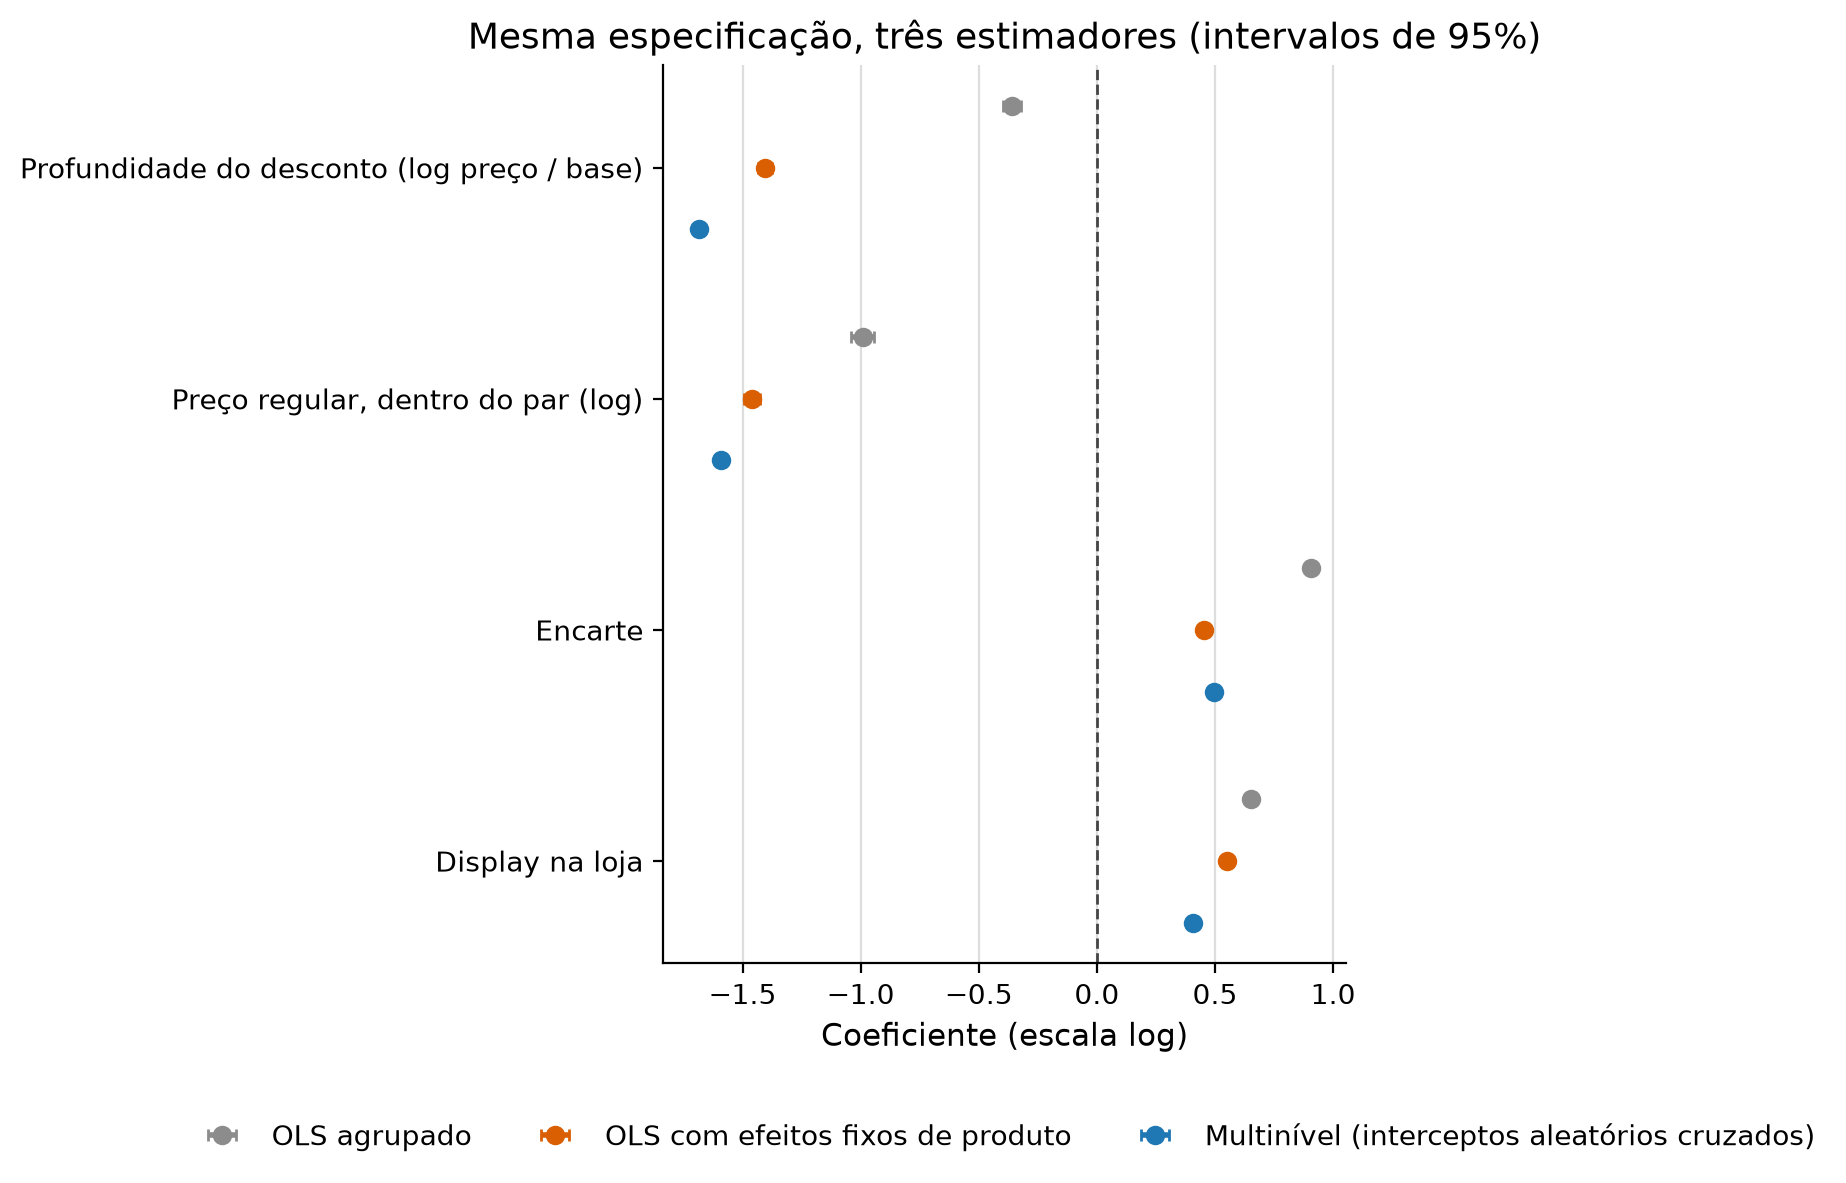

In [12]:
comparison = interpret.method_comparison_table(run.load_table("ols_pooled"), fixef)
fig = viz.plot_method_comparison(comparison, LANG)
estimates = comparison.pivot(index="term", columns="method", values="estimate")
display(estimates.loc[viz.COMPARISON_TERMS, ["ols_pooled", "ols_upc_fe", "multilevel"]])

A elasticidade ao desconto é de −0,359 no OLS agrupado, −1,405 no OLS com efeitos fixos de produto e −1,685 no multinível. O OLS agrupado atenua a elasticidade em cerca de 4,7 vezes e, ao mesmo tempo, infla os efeitos de encarte (0,908 contra 0,497 no multinível) e de display (0,651 contra 0,409). O OLS com efeitos fixos de produto se aproxima do multinível no desconto (−1,405) e no encarte (0,454), mas ainda diverge no display (0,551) e no preço regular dentro do par (−1,459 contra −1,592). Nenhum dos intervalos dos dois OLS contém a estimativa multinível do desconto, e esses intervalos, além disso, supõem linhas independentes, hipótese que o próprio notebook 02 mostrou ser inadequada (correlação de 75,4% entre semanas do mesmo par).

O OLS agrupado combina variação entre pares e dentro dos pares. Se descontos e promoções se concentram em pares com níveis de vendas diferentes, a composição dos pares pode mudar a associação estimada. Essa é uma explicação possível para a diferença observada entre a elasticidade de −0,36 no OLS agrupado e a de −1,69 no multinível.

## 8. Sensibilidade: sem as linhas de preço-base de fallback

A regra D8 revisada preenche o preço-base ausente apenas com a semana anterior do mesmo par. Quando não há histórico, vale `BASE_PRICE = PRICE`, e o desconto da linha é zerado. A tabela a seguir conta as linhas de fallback do painel e do treino e as distribui por tipo de promoção.

In [13]:
fallback = train[train["BASE_FALLBACK"]]
counts = {"fallback_rows_panel": int(panel["BASE_FALLBACK"].sum()), "fallback_rows_train": len(fallback)}
display(pd.Series(counts).to_frame("n"))
display(interpret.promo_by_discount_band(fallback, LANG))

,n
fallback_rows_panel,141
fallback_rows_train,111


,Sem redução de preço,0-5%,5-10%,10-20%,20-30%,Acima de 30%
Sem promoção,0,0,0,0,0,0
Apenas TPR,0,0,0,0,0,0
Apenas encarte,18,0,0,0,0,0
Apenas display,69,0,0,0,0,0
Encarte e display,24,0,0,0,0,0


O painel tem 141 linhas com preço base de fallback, das quais 111 estão no treino. As linhas de treino têm 18 ocorrências só de encarte, 69 só de display e 24 dos dois. Todas registram desconto zero, mesmo nas semanas em que pode ter havido desconto. Para medir a sensibilidade ao fallback, o F3 foi reajustado por REML após excluir essas 111 linhas (`fixed_effects_no_fallback`).

In [14]:
run_nf = load_run("fixed_effects_no_fallback", "20261124-114601-c4b16e68")
print("run:", run_nf.run_id, "| nobs:", run_nf.load_json("sample")["nobs"])
nofb = interpret.compare_estimates(fixef, run_nf.load_table("fixef"))
main_terms = ~nofb["term"].str.startswith(("SIN_", "COS_"))
display(nofb[main_terms].rename(columns={"estimate_other": "estimate_no_fallback", "se_other": "se_no_fallback"}))

run: 20261124-114601-c4b16e68 | nobs: 346981


,term,estimate,std_error,estimate_no_fallback,se_no_fallback,difference,se_ratio
0,(Intercept),2.9610,0.1749,2.9508,0.1750,-0.0102,1.0002
1,LOG_DISC,-1.6852,0.0107,-1.6848,0.0107,0.0003,1.0002
2,LOG_BASE_DEV,-1.5921,0.0119,-1.5910,0.0119,0.0011,1.0006
3,LOG_BASE_MEAN,-0.8797,0.1054,-0.8710,0.1054,0.0086,1.0000
4,FEATURE,0.4972,0.0043,0.4972,0.0043,-0.0001,1.0008
5,DISPLAY,0.4087,0.0036,0.4090,0.0036,0.0003,1.0009
6,TPR_ONLY,-0.0412,0.0037,-0.0413,0.0037,-0.0000,1.0001
7,TREND,-0.0214,0.0018,-0.0215,0.0018,-0.0000,1.0001


Sem as linhas de fallback (346.981 linhas), as estimativas mudam muito pouco: o desconto vai de −1,6852 para −1,6848, o preço regular dentro do par, de −1,5921 para −1,5910 (diferença de 0,0011, a maior entre os termos de preço e promoção), o encarte fica em 0,4972, o display passa de 0,4087 para 0,4090 e a TPR de −0,0412 para −0,0413. A maior diferença é a do termo de média do par, de −0,8797 para −0,8710 (0,0086). O efeito da regra é, portanto, desprezível para as conclusões, e os erros-padrão não mudam de forma perceptível. Isso não elimina a limitação: nessas 111 linhas, o desconto realizado fica registrado como zero em semanas de encarte ou display.

## 9. Sensibilidade: leitura dentro do par com efeitos fixos de par e de semana

Como somente o preço regular foi decomposto em termos dentro e entre pares, o desconto e as variáveis de promoção ainda misturam variação dentro e entre pares. Para examinar a leitura dentro do par, foi ajustado um OLS com efeitos fixos de par e de semana, estimado por transformação *within* (Wooldridge, 2010), com erros-padrão agrupados por par (CR1; Cameron & Miller, 2015), nas mesmas 347.092 linhas de treino e 3.859 pares (execução `fe_sensitivity`). Os efeitos de semana absorvem os choques comuns, a sazonalidade e a tendência. A tabela põe as estimativas e os erros-padrão ao lado dos do F3.

In [15]:
run_fe = load_run("fe_sensitivity", "20261124-135553-5c4b797b")
print("run:", run_fe.run_id, "| nobs:", run_fe.load_json("sample")["nobs"])
within = interpret.compare_estimates(
    fixef, run_fe.load_table("fe_two_way"), se_col="se_cluster", term_map={"LOG_BASE_PRICE": "LOG_BASE_DEV"}
)
display(within.rename(columns={"estimate_other": "estimate_fe", "se_other": "se_cluster_fe"}))

run: 20261124-135553-5c4b797b | nobs: 347092


,term,estimate,std_error,estimate_fe,se_cluster_fe,difference,se_ratio
0,LOG_DISC,-1.6852,0.0107,-1.7031,0.0437,-0.0180,4.0839
1,LOG_BASE_DEV,-1.5921,0.0119,-1.5980,0.0297,-0.0059,2.4994
2,FEATURE,0.4972,0.0043,0.4924,0.0104,-0.0048,2.4295
3,DISPLAY,0.4087,0.0036,0.4047,0.0080,-0.0040,2.2192
4,TPR_ONLY,-0.0412,0.0037,-0.0427,0.0090,-0.0015,2.4278


As estimativas pontuais coincidem com as do F3 em até 0,02: o desconto é de −1,703 contra −1,685 (a maior diferença, de −0,018), o preço regular de −1,598 contra −1,592, o encarte de 0,492 contra 0,497, o display de 0,405 contra 0,409 e a TPR de −0,043 contra −0,041. A leitura dentro do par, com controle de tempo, confirma, portanto, as magnitudes do F3 também para o desconto e as flags, que não foram decompostos. A estimativa do desconto (−1,703) fica próxima da do multinível, e não da do OLS agrupado (−0,359).

Os erros-padrão agrupados por par são de 2,2 a 4,1 vezes maiores que os de Wald do F3 (a razão é de 4,1 para o desconto e de 2,2 para o display). Os intervalos de Wald do F3 são, assim, condicionais à especificação do F3 e estreitos demais para a incerteza que os dados comportam, o que a seção seguinte detalha.

## 10. Dependência residual: defasagens e choques comuns de semana

Os intervalos de Wald do F3 supõem resíduos independentes depois de considerados os efeitos aleatórios. A hipótese foi verificada reajustando o F3 por REML no treino (execução `residual_diagnostics`) e examinando os resíduos condicionais, isto é, aqueles de que se descontaram os efeitos fixos e os efeitos aleatórios previstos. O primeiro gráfico traz a correlação, dentro do mesmo par, entre o resíduo da semana t e o da semana t + k, com os pares agrupados.

run: 20261124-115221-9c67822a | nobs: 347092


,lag,corr,n_pairs_of_obs
0,1,0.1958,327045
1,2,0.1173,323155
2,3,0.0922,319363
3,4,0.0960,315637


,corr,n
0,0.1920,343233


,CATEGORY,corr,n_pairs_of_obs
0,BAG SNACKS,0.2531,80998
1,COLD CEREAL,0.2185,113046
2,FROZEN PIZZA,0.1789,67712
3,ORAL HYGIENE PRODUCTS,0.1426,65289


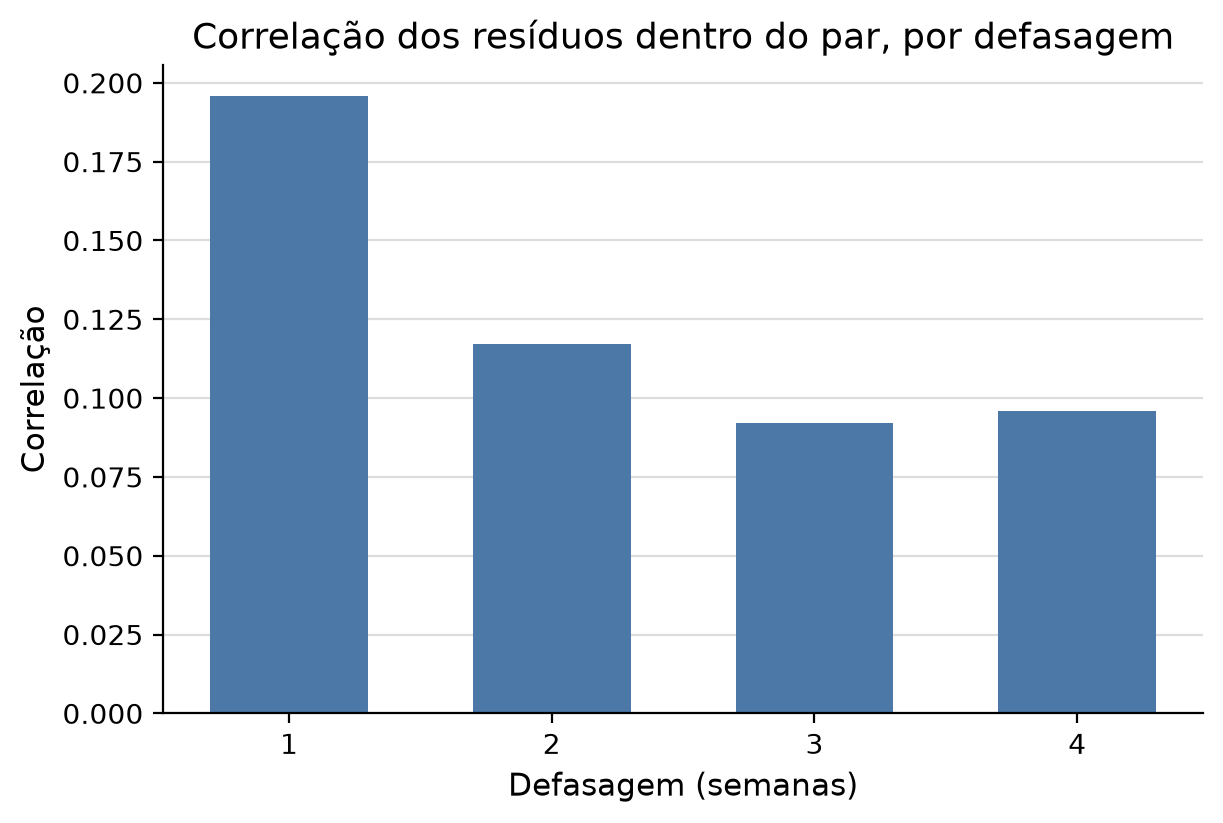

In [16]:
run_diag = load_run("residual_diagnostics", "20261124-115221-9c67822a")
print("run:", run_diag.run_id, "| nobs:", run_diag.load_json("key_numbers")["nobs"])
lag_corr = run_diag.load_table("lag_corr")
fig = viz.plot_residual_lag_corr(lag_corr, LANG)
display(lag_corr)
display(run_diag.load_table("consecutive"))
display(run_diag.load_table("lag1_by_category"))

A correlação entre semanas consecutivas do mesmo par é de 0,196 (327.045 comparações), e as defasagens de 2, 3 e 4 semanas têm 0,117, 0,092 e 0,096. A dependência decai, mas não desaparece em quatro semanas. Entre linhas consecutivas observadas do par, qualquer que seja o intervalo de calendário, a correlação é de 0,192 (343.233 comparações). A correlação de defasagem 1 varia por categoria, de 0,143 em higiene oral a 0,253 em snacks, com cereal em caixa e pizza congelada em valores intermediários.

,value
sigma2,0.269424
n_weeks,104.000000
var_week_means,0.007861
var_expected_independent,0.000081
variance_ratio,97.192216
share_week,0.028161
share_week_expected,0.000297
autocorr_week_means,-0.004669
share_category_week,0.063634
share_category_week_expected,0.001196


,value
weeks_outside_band,79
weeks,104
largest_shock_week,61
largest_shock_week_end,2010-03-17
largest_shock_mean_resid,-0.5824


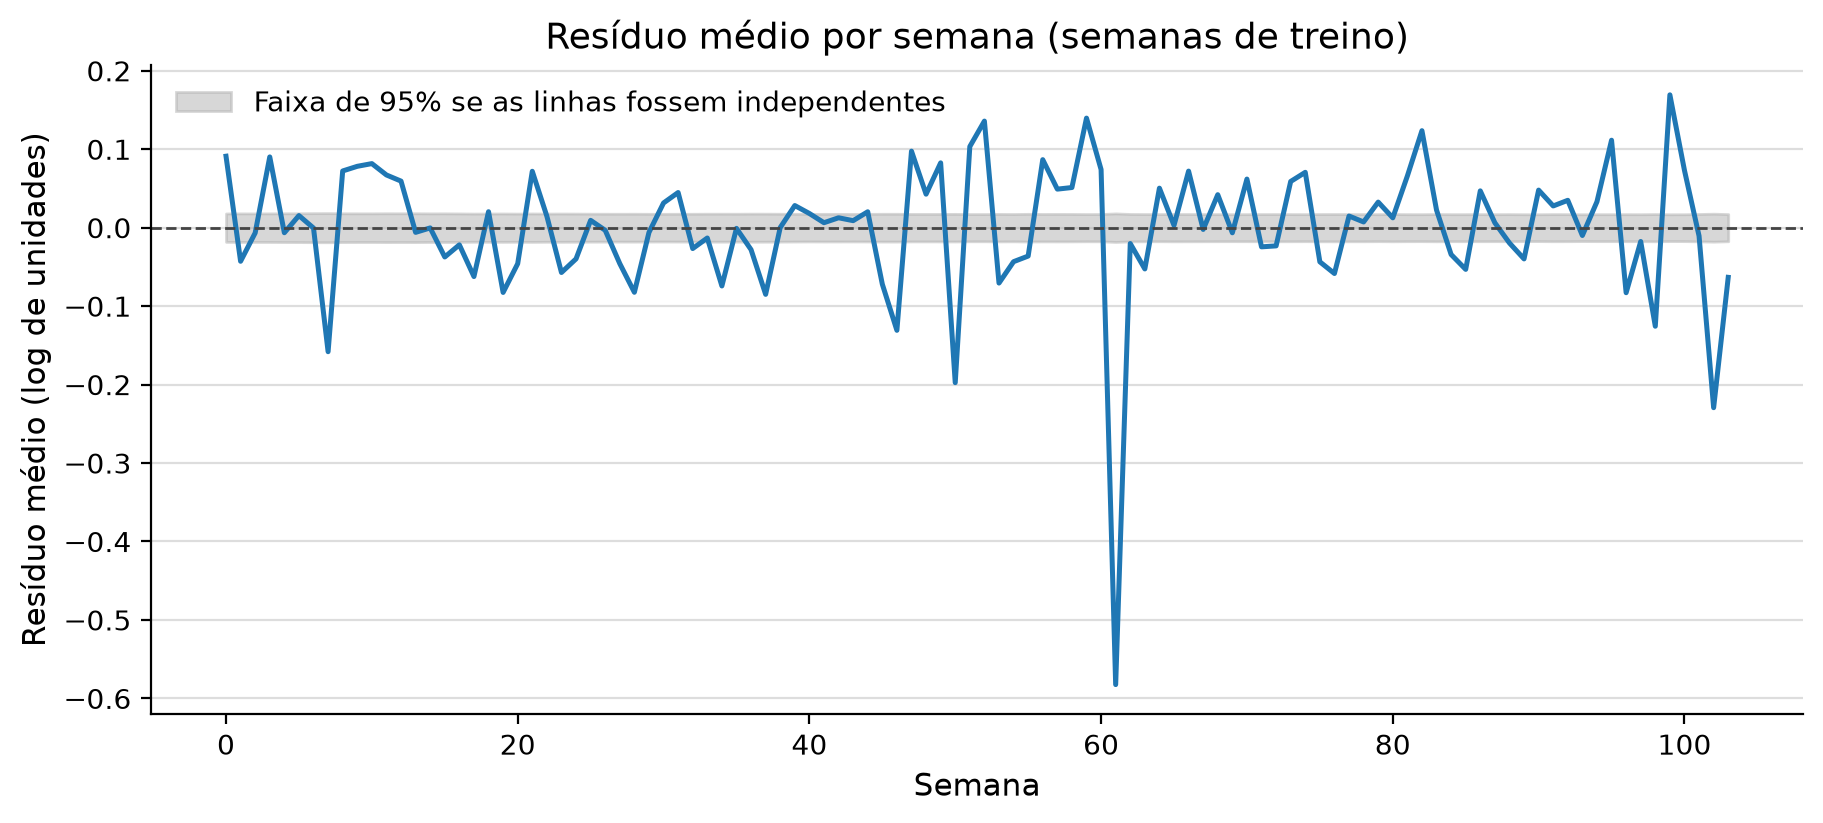

In [17]:
shocks = run_diag.load_table("week_shocks")
fig = viz.plot_week_shocks(shocks, LANG)
with pd.option_context("display.float_format", "{:,.6f}".format):
    display(run_diag.load_table("week_summary").iloc[0].to_frame("value"))
largest = shocks.loc[shocks["mean_resid"].abs().idxmax()]
week_end = panel.loc[panel["WEEK"] == largest["WEEK"], "WEEK_END_DATE"].iloc[0].date().isoformat()
outside = int((shocks["mean_resid"].abs() > 1.96 * shocks["expected_sd"]).sum())
display(
    pd.Series(
        {
            "weeks_outside_band": outside,
            "weeks": len(shocks),
            "largest_shock_week": int(largest["WEEK"]),
            "largest_shock_week_end": week_end,
            "largest_shock_mean_resid": largest["mean_resid"],
        },
        dtype=object,
    ).to_frame("value")
)

O segundo gráfico mostra o resíduo médio de cada semana de treino com a faixa de 95% esperada se as linhas fossem independentes. A variância das médias semanais é de 0,007861, contra 0,000081 esperado sob independência, uma razão de cerca de 97. A participação das semanas na soma de quadrados dos resíduos é de 2,8%, contra 0,03% esperado, e a da combinação categoria × semana é de 6,4%, contra 0,12% esperado. Há, portanto, choques comuns a todas as linhas de uma semana, em especial por categoria. A autocorrelação de defasagem 1 das médias semanais é de −0,005, ou seja, esses choques não persistem de uma semana para a seguinte. Em 79 das 104 semanas, a média fica fora da faixa. A maior é a da semana 61 (semana encerrada em 2010-03-17), com resíduo médio de −0,582, contra um desvio-padrão esperado de 0,009.

Os resíduos marginais, que não descontam os efeitos aleatórios, também foram guardados na execução. Eles refletem sobretudo os efeitos de loja, produto e par, e não informam sobre os intervalos de Wald.

Os resíduos condicionais de F3 têm correlação serial positiva dentro do par e choques comuns de semana e categoria. Os diagnósticos indicam que a dependência residual amplia a incerteza em relação aos intervalos de Wald, embora as estimativas pontuais fiquem próximas das do modelo com efeitos fixos de par e de semana (seção 9). No estimador de efeitos fixos, os erros-padrão agrupados por par e por semana (Cameron et al., 2011) ficam de 4,1 a 7,4 vezes os de Wald do F3, com maior contribuição do agrupamento por semana. Os sinais das estimativas se mantêm (`fe_sensitivity`, emenda E4 do registro de decisões).

## 11. Limitações

A rede decide preços e promoções. Ela pode planejar promoções para semanas de demanda alta ou aplicar descontos em resposta a estoques e à concorrência. Nesse caso, parte da associação estimada reflete os critérios de seleção das promoções e dos preços (endogeneidade, Villas-Boas & Winer, 1999). Uma recomendação de preço ou um ROI incremental exige identificação causal e dados de margem. A especificação log-log aproxima a relação com uma elasticidade constante para descontos como 10% e 30%. As comparações entre promoções ficam restritas pelas faixas de desconto em que elas aparecem (seção 4).

A dependência residual foi medida (seção 10): há correlação serial de 0,196 entre semanas consecutivas do mesmo par e choques comuns de semana. Ela não foi modelada, e os intervalos de Wald do F3 são condicionais à sua especificação e estreitos demais, como indicam os erros-padrão agrupados da seção 9, de 2,2 a 4,1 vezes maiores. Além disso, a formulação (a decomposição de preço da D12 e as demais) foi motivada pela exploração inicial do painel, que incluiu as 52 semanas finais, e é uma decisão de desenvolvimento. Nenhum modelo foi ajustado nessas semanas, e nenhuma comparação preditiva foi calculada nelas.

Foram modeladas as semanas com vendas registradas no par (D3). Semanas sem registro podem corresponder a vendas zero ou a ruptura. O F3 estima uma elasticidade comum a lojas e produtos. A variação da elasticidade entre eles é examinada no notebook 04.

## 12. Conclusões e próximo passo

Com a hierarquia mantida (interceptos aleatórios de loja, de produto e de par), uma redução de 10% na razão entre preço e preço base está associado a cerca de 19,4% mais unidades (elasticidade de −1,685), e um preço regular 10% maior a cerca de 14,1% menos. O encarte (+64,4%) e o display (+50,5%) estão associados a mais unidades além do desconto, e a flag de TPR tem coeficiente de −0,041 (−4,0%), valor que depende de comparar semanas sem promoção com o mesmo desconto, comparação que os dados quase não contêm. Os cenários de TPR da seção 4 estimam +14,6% com 10% de desconto e +39,8% com 20%. Ambos têm suporte nos dados. O encarte sem desconto tem o menor suporte observado (0,3% do treino). A tendência é de −2,1% por ano. A sazonalidade varia de −4,2% a +6,6% em relação à semana média, uma faixa menor que a variação de 19,4% associada ao preço. Todos esses valores são associações condicionais em semanas com transações registradas.

Preço e promoção explicam 34,4% da variância semanal dentro do par e 29,3% da variância entre produtos, e os pequenos valores negativos de pseudo-R² nos níveis de loja e de par são um artefato conhecido. O OLS agrupado estima uma elasticidade ao desconto de −0,36, contra −1,69 do multinível. A exclusão das 111 linhas de fallback quase não altera as estimativas, e a regressão com efeitos fixos de par e de semana reproduz as estimativas pontuais do F3 em até 0,02, com erros-padrão agrupados de 2,2 a 4,1 vezes maiores. Os resíduos condicionais têm correlação de 0,196 entre semanas consecutivas e apresentam choques comuns de semana. A dependência residual indica que os intervalos de Wald do F3 subestimam a incerteza. Os erros-padrão agrupados por par e por semana, registrados na emenda E4, são de 4,1 a 7,4 vezes os de Wald do F3.

O notebook 04 apresenta os resultados do protocolo pré-registrado P1, aprovado com emendas, sobre se deixar a elasticidade ao desconto variar entre lojas e produtos melhora a previsão fora da amostra.

## Referências

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software, 67*(1), 1–48. https://doi.org/10.18637/jss.v067.i01

Bijmolt, T. H. A., van Heerde, H. J., & Pieters, R. G. M. (2005). New empirical generalizations on the determinants of price elasticity. *Journal of Marketing Research, 42*(2), 141–156. https://doi.org/10.1509/jmkr.42.2.141.62296

Blattberg, R. C., & Neslin, S. A. (1989). Sales promotion: The long and the short of it. *Marketing Letters, 1*(1), 81–97. https://doi.org/10.1007/BF00436151

Cameron, A. C., & Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources, 50*(2), 317–372. https://doi.org/10.3368/jhr.50.2.317

Cameron, A. C., Gelbach, J. B., & Miller, D. L. (2011). Robust inference with multiway clustering. *Journal of Business & Economic Statistics, 29*(2), 238–249. https://doi.org/10.1198/jbes.2010.07136

Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/

Mundlak, Y. (1978). On the pooling of time series and cross section data. *Econometrica, 46*(1), 69–85. https://doi.org/10.2307/1913646

Pinheiro, J. C., & Bates, D. M. (2000). *Mixed-effects models in S and S-PLUS*. Springer. https://doi.org/10.1007/b98882

Raudenbush, S. W., & Bryk, A. S. (2002). *Hierarchical linear models: Applications and data analysis methods* (2nd ed.). Sage. (verificação parcial: ano da edição não conferido em fonte primária)

Tellis, G. J. (1988). The price elasticity of selective demand: A meta-analysis of econometric models of sales. *Journal of Marketing Research, 25*(4), 331–341. https://doi.org/10.1177/002224378802500401

Villas-Boas, J. M., & Winer, R. S. (1999). Endogeneity in brand choice models. *Management Science, 45*(10), 1324–1338. https://doi.org/10.1287/mnsc.45.10.1324

Wooldridge, J. M. (2010). *Econometric analysis of cross section and panel data* (2nd ed.). MIT Press. (verificação parcial: ano da edição não conferido em fonte primária)